In [1]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from pathlib import Path
from dask.distributed import Client
import sys, os
import warnings
warnings.filterwarnings("ignore")

In [2]:
client = Client(
    n_workers=24,
    threads_per_worker=1
)
client

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: /proxy/39159/status,
Dashboard: /proxy/39159/status,Workers: 24
Total threads: 24,Total memory: 95.00 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:36737,Workers: 0
Dashboard: /proxy/39159/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:40629,Total threads: 1
Dashboard: /proxy/40195/status,Memory: 3.96 GiB
Nanny: tcp://127.0.0.1:36193,


In [3]:
YEAR = "2025"
MONTH = "01"

In [14]:
def open_files(root_path, preprocess=None, filename_tag=None):
    '''
    Use xarray's open_mfdataset() to open netcdf files, using arguments optimised for
    opening climate datasets quickly and efficiently.

    INPUTS
    root_path: parent directory where netcdf files are located
    preprocess: preprocessing function to pass into open_mfdataset()
    filename_tag: condition for the filename when globbing files

    OUTPUT
    xarray data combining all netcdf files recursively globbed from root_path, where the
    filename contains "filename_tag" and "preprocess" is applied to the data
    '''
    
    if filename_tag:
        files = sorted([f for f in root_path.rglob(f'*{filename_tag}*.nc')])
    else:
        files = sorted([f for f in root_path.rglob('*.nc')])

    return xr.open_mfdataset(
        files,
        preprocess = preprocess,
        concat_dim='time',
        combine='nested',
        data_vars='minimal',
        coords='minimal',
        compat='override',
        parallel=True,
        chunks='auto'
    )

In [15]:
def preprocess(ds):
    return ds.sel(
        latitude=slice(-35, -28.5),
        longitude=slice(145, 151.5)
    )[["surface_global_irradiance", "solar_elevation"]]

him_path = Path(f"/g/data/rv74/satellite-products/arc/der/himawari-ahi/solar/p1s/v1.1/{YEAR}/{MONTH}")
ds = open_files(him_path, preprocess=preprocess)


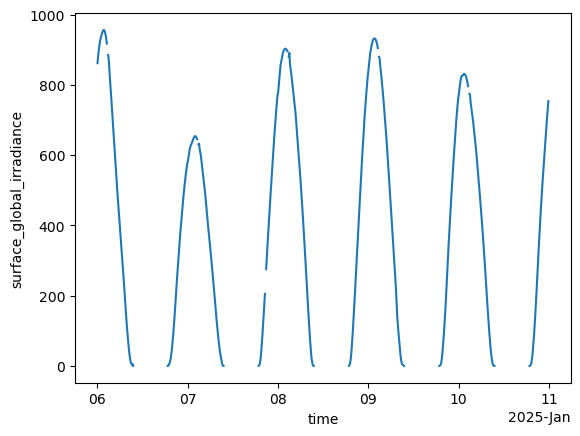

In [18]:
ds.surface_global_irradiance.sel(
    time=slice("2025-01-06", "2025-01-10")
).mean(
    ["latitude", "longitude"]
).plot()